In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#plt.rcParams["figure.figsize"] = (6,3)

In [3]:
def plot_data(df, optimizer):
    fig, ax = plt.subplots()
    for key, grp in df.groupby(['n_samples', 'test_size']):
        label = f'{key[0]} Samples - {100-key[1]}/{key[1]} split'
        ax = grp.plot(ax=ax, kind='line', x='iterations', y='r2', label=label)
    ax.set_title(f'{str(optimizer).upper()} Optimizer\n R2 Scores by Iterations', fontdict={'fontweight':'bold'})
    ax.set_xlabel(xlabel='Iterations')
    ax.xaxis.get_label().set_fontstyle('italic')
    ax.yaxis.get_label().set_fontstyle('italic')
    ax.set_ylabel(ylabel="R2")
    ax.grid(visible=True)
    plt.legend(bbox_to_anchor=(1.55, 0.6),loc='center right')
    plt.show()

In [4]:
df = pd.read_csv('results-final.csv')
df['training_time'] = df['training_time'].divide(3600)
df = df.round(4)

In [5]:
df.sort_values(['r2'], ascending=False).head(10)

,n_features,n_targets,n_samples,test_size,optimizer,iterations,training_time,prediction_time,r2,mae,mse,rmse
69,3,2,500,30,lbfgsb,500,3.0381,0.3317,0.9504,0.0377,0.0029,0.0539
62,3,2,500,30,lbfgsb,300,3.4232,0.3060,0.9501,0.0378,0.0029,0.0540
46,3,2,500,30,lbfgsb,100,2.4656,0.3058,0.9461,0.0398,0.0031,0.0561
76,3,2,500,30,slsqp,500,0.7934,0.3114,0.9415,0.0438,0.0034,0.0586
74,3,2,500,30,slsqp,300,0.8991,0.3037,0.9407,0.0418,0.0035,0.0588
70,3,2,500,30,slsqp,100,0.6677,0.3150,0.9381,0.0423,0.0036,0.0601
40,3,2,500,40,lbfgsb,100,2.0474,0.4342,0.9369,0.0496,0.0039,0.0624
75,3,2,500,40,lbfgsb,500,3.7445,0.3938,0.9368,0.0497,0.0039,0.0625
64,3,2,500,40,lbfgsb,300,4.7603,0.4112,0.9368,0.0497,0.0039,0.0625
77,3,2,500,40,slsqp,100,0.8704,0.3931,0.9337,0.0496,0.0041,0.0641


In [6]:
df.sort_values(['r2'], ascending=False).head(10).to_html('Top_10_Quantum.html', index=False)

In [12]:
df.sort_values(['r2'], ascending=False).head(10).to_csv("top_10_quantum.csv", index=False)

In [7]:
df_cobyla = df[(df['optimizer'] == 'cobyla')]
df_cobyla.sort_values(['r2'], ascending=False).head(10).to_html('Top_10_Quantum_COBYLA.html', index=False)


In [13]:
df_cobyla.sort_values(['r2'], ascending=False).head(10).to_csv('Top_10_Quantum_COBYLA.csv', index=False)


In [ ]:

df_lbfgsb = df[(df['optimizer'] == 'lbfgsb')]
df_lbfgsb.sort_values(['r2'], ascending=False).head(10).to_html('Top_10_Quantum_LBFGSB.html', index=False)

df_slsqp = df[(df['optimizer'] == 'slsqp')]
df_slsqp.sort_values(['r2'], ascending=False).head(10).to_html('Top_10_Quantum_SLSQP.html', index=False)

df_adam = df[(df['optimizer'] == 'adam')]
df_adam.sort_values(['r2'], ascending=False).head(10).to_html('Top_10_Quantum_ADAM.html', index=False)



In [8]:
"""
sample_sizes = [100, 500, 1000]
test_sizes = [20, 30, 40]
"""
pd.set_option('display.max_rows', None)
#df[(df['n_samples']==100)].to_html('100_samples.html', index=False)
#df[(df['n_samples']==500)].to_html('500_samples.html', index=False)
#df[(df['n_samples']==1000)].to_html('1000_samples.html', index=False)

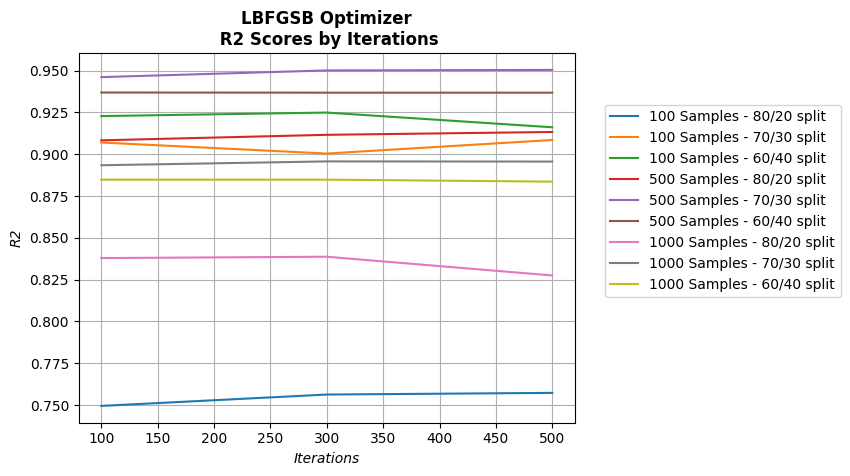

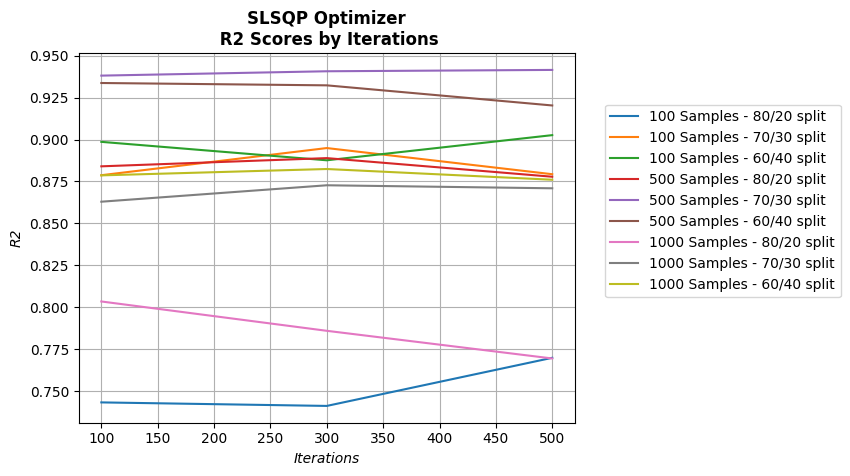

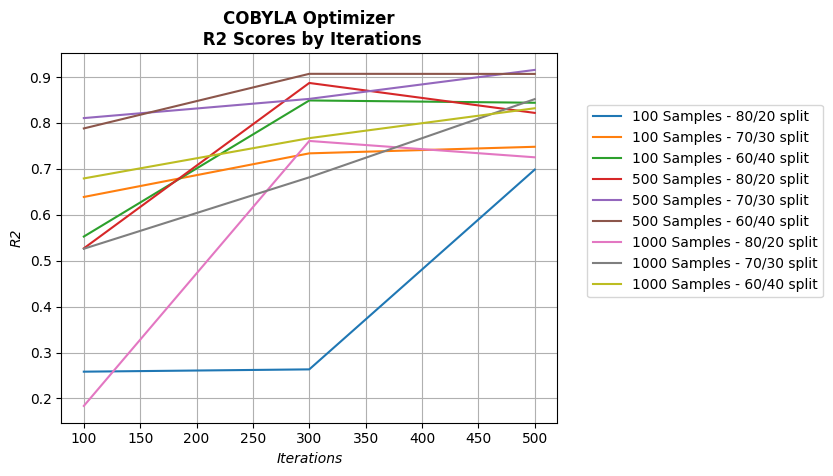

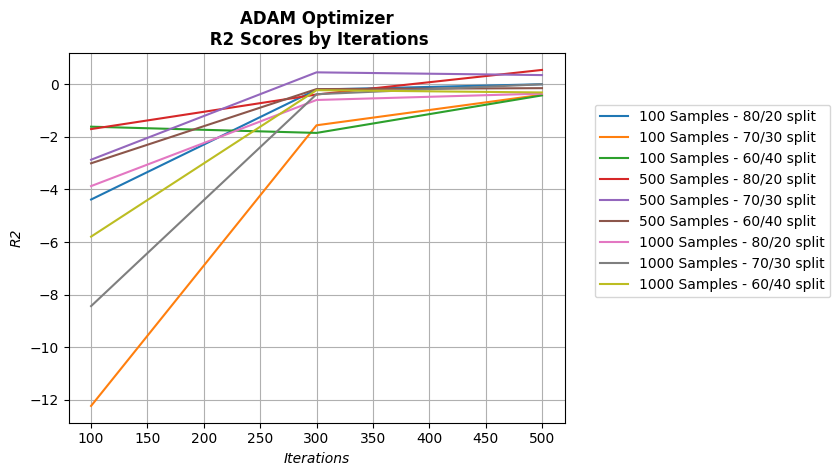

In [9]:
sample_sizes = [100, 500, 1000]
test_sizes = [20, 30, 40]
performance_metrics = ['r2', 'mae', 'mse', 'rmse']
optimizers = ['lbfgsb', 'slsqp', 'cobyla', 'adam']

for optimizer in optimizers:
    df_by_optimizer = df[(df['optimizer'] == optimizer)]
    plot_data(df_by_optimizer, optimizer)

In [10]:
def plot_10_data(df):
    fig, ax = plt.subplots()
    for key, grp in df.groupby(['optimizer','n_samples', 'test_size', 'iterations']):
        label = f'{key[0]} Samples - {100-key[2]}/{key[2]} split'
        ax = grp.plot(ax=ax, kind='bar', x=key, y='r2', label=label)
    ax.set_title(f'Top 10 Models by R2 Scores', fontdict={'fontweight':'bold'})
    ax.set_xlabel(xlabel='Iterations')
    ax.xaxis.get_label().set_fontstyle('italic')
    ax.yaxis.get_label().set_fontstyle('italic')
    ax.set_ylabel(ylabel="R2")
    ax.grid(visible=True)
    plt.legend(bbox_to_anchor=(1.55, 0.6),loc='center right')
    plt.show()

In [26]:

df_top_10 = df.sort_values(['r2'], ascending=False).head(10)
df_top_10


,n_features,n_targets,n_samples,test_size,optimizer,iterations,training_time,prediction_time,r2,mae,mse,rmse
69,3,2,500,30,lbfgsb,500,3.0381,0.3317,0.9504,0.0377,0.0029,0.0539
62,3,2,500,30,lbfgsb,300,3.4232,0.3060,0.9501,0.0378,0.0029,0.0540
46,3,2,500,30,lbfgsb,100,2.4656,0.3058,0.9461,0.0398,0.0031,0.0561
76,3,2,500,30,slsqp,500,0.7934,0.3114,0.9415,0.0438,0.0034,0.0586
74,3,2,500,30,slsqp,300,0.8991,0.3037,0.9407,0.0418,0.0035,0.0588
70,3,2,500,30,slsqp,100,0.6677,0.3150,0.9381,0.0423,0.0036,0.0601
40,3,2,500,40,lbfgsb,100,2.0474,0.4342,0.9369,0.0496,0.0039,0.0624
75,3,2,500,40,lbfgsb,500,3.7445,0.3938,0.9368,0.0497,0.0039,0.0625
64,3,2,500,40,lbfgsb,300,4.7603,0.4112,0.9368,0.0497,0.0039,0.0625
77,3,2,500,40,slsqp,100,0.8704,0.3931,0.9337,0.0496,0.0041,0.0641


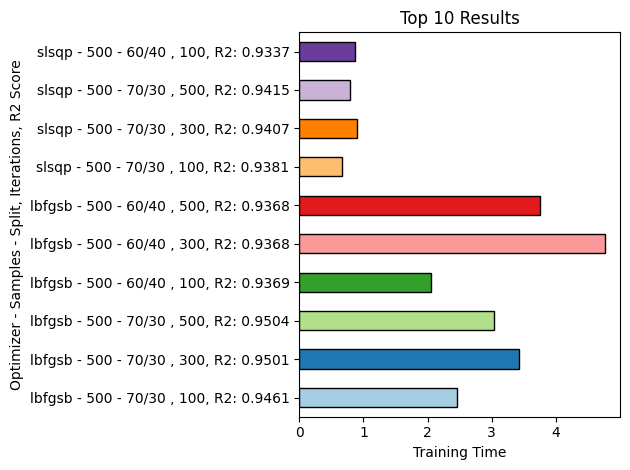

In [34]:
# Convert the MultiIndex DataFrame to a regular DataFrame
df_top_10_reset = df_top_10.reset_index()

# Create a new column with the desired label strings
df_top_10_reset['label'] = df_top_10_reset.apply(lambda row: f"{row['optimizer']} - {row['n_samples']} - {100-row['test_size']}/{row['test_size']} , {row['iterations']}, R2: {row['r2']}", axis=1)

# Set the MultiIndex back to the DataFrame
df_top_10_with_label = df_top_10_reset.set_index(['optimizer','n_samples', 'test_size', 'iterations', 'r2'])

# Plot the data using the 'label' column as y-labels
ax = df_top_10_with_label.plot(kind='barh', y='training_time', legend=False, color=plt.cm.Paired(np.arange(len(df_top_10_with_label))), edgecolor='black')

# Set the custom labels for the bars
ax.set_yticklabels(df_top_10_with_label['label'])

# Customize the plot appearance if needed (e.g., axis labels, title, etc.)
plt.xlabel('Training Time')
plt.ylabel('Optimizer - Samples - Split, Iterations, R2 Score')
plt.title('Top 10 Results')
plt.tight_layout()

# Show the plot
plt.show()

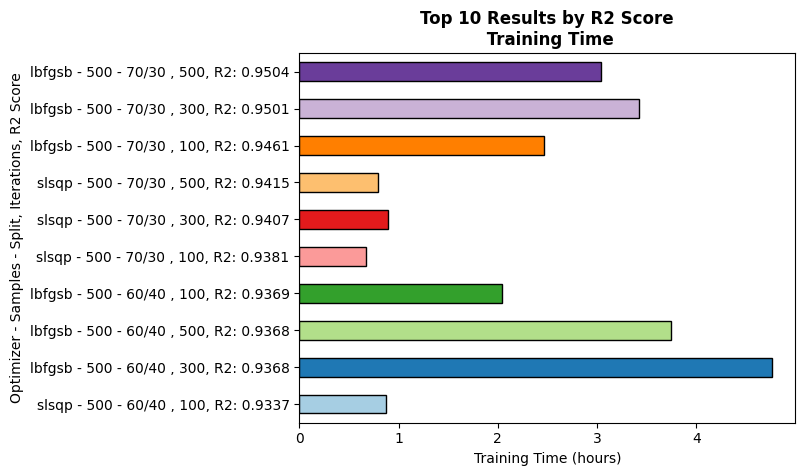

In [39]:
df_top_10_reset = df_top_10.reset_index()

# Create a new column with the desired label strings
df_top_10_reset['label'] = df_top_10_reset.apply(lambda row: f"{row['optimizer']} - {row['n_samples']} - {100-row['test_size']}/{row['test_size']} , {row['iterations']}, R2: {row['r2']}", axis=1)

# Sort the DataFrame by the 'r2' column
df_top_10_sorted = df_top_10_reset.sort_values(by='r2', ascending=True)

# Set the MultiIndex back to the DataFrame
df_top_10_with_label = df_top_10_sorted.set_index(['optimizer','n_samples', 'test_size', 'iterations', 'r2'])

# Plot the data using the 'label' column as y-labels
ax = df_top_10_with_label.plot(kind='barh', y='training_time', legend=False, color=plt.cm.Paired(np.arange(len(df_top_10_with_label))), edgecolor='black')

# Set the custom labels for the bars
ax.set_yticklabels(df_top_10_with_label['label'])

# Customize the plot appearance if needed (e.g., axis labels, title, etc.)
plt.xlabel('Training Time (hours)')
plt.ylabel('Optimizer - Samples - Split, Iterations, R2 Score')
plt.title('Top 10 Results by R2 Score\n Training Time',fontdict={'fontweight':'bold'})
#plt.tight_layout()

# Show the plot
plt.show()